In [ ]:
import numpy as np
from tqdm import tqdm
import torch
import torch.nn as nn
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torch.optim.lr_scheduler import StepLR, ReduceLROnPlateau
import torchvision.transforms as transforms
from torch.utils.data import random_split
from src.utils.custom_dataset import *
import matplotlib.pyplot as plt
import wandb

In [2]:
PROCESSED_PATH = 'dataset/processed/'
IN = "IN/"
OUT = "OUT/"

### 1. 데이터세트 지정
- dataset 지정 (Customdataset Class 사용)

In [21]:
dataset = CustomDataset(transform=transforms.Compose([transforms.ToTensor()]),
                        target_transform=transforms.Compose([transforms.ToTensor()]))

In [22]:
all_dataset = []
for idx in range(len(dataset)):
    if idx % 10 == 0 :
        all_dataset.append(temp)
        temp = []
    else:
        temp.append(dataset[idx])

- dataset 분할 (random_split 사용)

In [14]:
dataset_size = len(dataset)
train_size = int(dataset_size * 0.8)
validation_size = int(dataset_size * 0.1)
test_size = dataset_size - train_size - validation_size

train_dataset, validation_dataset, test_dataset = random_split(dataset,[train_size,validation_size,test_size],
                                                               generator=torch.Generator().manual_seed(42))
print(f"Training Data Size : {len(train_dataset)}")
print(f"Validation Data Size : {len(validation_dataset)}")
print(f"Testing Data Size : {len(test_dataset)}")

Training Data Size : 1448
Validation Data Size : 181
Testing Data Size : 181


- DataLoader 설정

In [ ]:
train_dataloader = DataLoader(train_dataset, batch_size=4, shuffle=True)
validation_dataloader = DataLoader(validation_dataset, batch_size=4, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=4, shuffle=True)

### 2. 데이터 확인

In [41]:
check_dataloader = DataLoader(train_dataset, batch_size=1, shuffle=True)
check_ux_in_lst = []
check_ux_out_lst = []
for idx,(ux_in,uy_in,p_in,bdr,st,sv,ux_out,uy_out,p_out) in enumerate(check_dataloader):
    check_ux_in_lst.append(ux_in)    
    check_ux_out_lst.append(ux_out)

tensor(0.0121, dtype=torch.float64)
tensor(-0.0179, dtype=torch.float64)


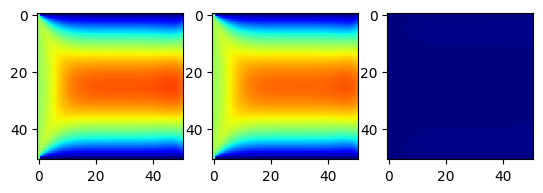

In [57]:
plot_idx = 80
plot_in = check_ux_in_lst[plot_idx][0][0]
plot_out = check_ux_out_lst[plot_idx][0][0]
plot_diff = plot_out-plot_in
print(torch.max(plot_diff))
print(torch.min(plot_diff))
plt.subplot(1,3,1)
plt.imshow(plot_in,vmin=0,vmax=1,cmap='jet')
plt.subplot(1,3,2)
plt.imshow(plot_out,vmin=0,vmax=1,cmap='jet')
plt.subplot(1,3,3)
plt.imshow(plot_diff,vmin=0,vmax=1,cmap='jet')

### 3. 모델 로드

In [58]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
from src.model.model import *
model = TransUNet().to(device)

In [ ]:
def train_loop(dataloader,model,loss_fn,optimizer):
    
    size = len(dataloader.dataset) # 입력 데이터세트의 총 길이  : 320
    num_batches = len(dataloader) # 배치 총 개수 (320/4 = 80) 
    train_loss = 0 # loss 초기화

    # train_loop 
    # ux_input,uy_input,p_input,bdr_input,st_input,sv_input,\
    # ux_output,uy_output,p_output

    for batch, (ux_in,uy_in,p_in,bdr,st,sv,ux_out,uy_out,p_out) in enumerate(tqdm(dataloader)): 
        ux_in = ux_in.type(torch.float32).to(device)    # torch.Size([4, 1, 51, 51])
        uy_in = uy_in.type(torch.float32).to(device)    # torch.Size([4, 1, 51, 51])
        p_in = p_in.type(torch.float32).to(device)      # torch.Size([4, 1, 51, 51])
        bdr = bdr.type(torch.float32).to(device)        # torch.Size([4, 1, 51, 51])
        st = st.type(torch.int32).to(device)            # torch.Size([4, 4, 1]), embedding 으로 넘어가기때문에 int 형
        sv = sv.type(torch.float32).to(device)          # torch.Size([4, 4, 1])
        ux_out = ux_out.type(torch.float32).to(device)  # torch.Size([4, 1, 51, 51])
        uy_out = uy_out.type(torch.float32).to(device)  # torch.Size([4, 1, 51, 51])
        p_out = p_out.type(torch.float32).to(device)    # torch.Size([4, 1, 51, 51])

        inp = torch.concat([ux_in,uy_in,p_in,bdr],axis=1)
        X = [inp,st,sv]
        y = torch.concat([ux_out,uy_out,p_out],axis=1)
        
        # 모델 학습
        pred = model(X)
        loss = loss_fn(pred,y)
        optimizer.zero_grad() # 이전 루프에서 각 파라미터들에 저장된 .grad를 초기화
        loss.backward() # 각 파라미터들의 .grad값에 변화정도가 저장이 됨.
        optimizer.step() # 최적화함수에 맞게, 각 파라미터 업데이트

        # Loss 계산
        train_loss += loss.item() # item()을 통해, 변수에서 값만 가져옴

    train_loss /= num_batches
    print(f"Train loss: {train_loss:>8f} \n")
    
    return train_loss

def validation_loop(dataloader,model,loss_fn):

    size = len(dataloader.dataset) # 입력 데이터세트의 총 길이 : 40
    num_batches = len(dataloader) # 배치 총 개수 (40/4 = 10)
    validation_loss = 0 # loss 초기화

    with torch.no_grad():
        for ux_in,uy_in,p_in,bdr,st,sv,ux_out,uy_out,p_out in tqdm(dataloader):
            ux_in = ux_in.type(torch.float32).to(device)
            uy_in = uy_in.type(torch.float32).to(device)
            p_in = p_in.type(torch.float32).to(device)
            bdr = bdr.type(torch.float32).to(device)
            st = st.type(torch.int32).to(device) # embedding 으로 넘어가기때문에 int 형
            sv = sv.type(torch.float32).to(device)
            ux_out = ux_out.type(torch.float32).to(device)
            uy_out = uy_out.type(torch.float32).to(device)
            p_out = p_out.type(torch.float32).to(device)


            inp = torch.concat([ux_in,uy_in,p_in,bdr],axis=1)
            X = [inp,st,sv]
            y = torch.concat([ux_out,uy_out,p_out],axis=1)
            
            # 모델 예측 & Loss 계산
            pred = model(X)
            loss = loss_fn(pred,y)
            validation_loss += loss.item() # item()을 통해, 변수에서 값만 가져옴
            
    validation_loss /= num_batches
    print(f"Validation loss: {validation_loss:>8f} \n")
    return validation_loss

In [ ]:
learning_rate = 1e-3
epochs = 200
loss_fn = torch.nn.L1Loss()
optimizer = torch.optim.Adam(model.parameters(),lr=learning_rate)

train_loss_all = []
validation_loss_all = []
best_validation_loss = float('inf')

for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train_loss = train_loop(train_dataloader, model, loss_fn, optimizer)
    train_loss_all.append(train_loss)
    validation_loss = validation_loop(validation_dataloader, model, loss_fn)
    validation_loss_all.append(validation_loss)
    if validation_loss < best_validation_loss:
            best_validation_loss = validation_loss
            torch.save(model.state_dict(), 'best_model_weights.pth')  # 가중치 저장
            
print("학습완료")